In [6]:
import import_ipynb
import data_analysis
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [7]:
reg_features = ['Income_Category', 'Card_Category_Blue', 'Total_Trans_Amt',
                 'Card_Category_Silver', 'Total_Trans_Ct', 'Card_Category_Gold',
                 'Dependent_count']

Xr_train = data_analysis.Xr_train[reg_features]
Xr_test = data_analysis.Xr_test[reg_features]
yr_train = data_analysis.yr_train
yr_test = data_analysis.yr_test


continuous_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Dependent_count']

scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled = Xr_test.copy()

Xr_train_scaled[continuous_cols] = scaler.fit_transform(Xr_train[continuous_cols])
Xr_test_scaled[continuous_cols] = scaler.transform(Xr_test[continuous_cols])

In [ ]:
class BayesianLinearRegression:
    def __init__(self, alpha=1.0, beta=1.0):
        self.alpha = alpha
        self.beta = beta
        self.mu_post = None
        self.Sigma_post = None

    def fit(self, X, y):
        X_b = np.c_[np.ones((len(X), 1)), X]
        d = X_b.shape[1]
        y = np.asarray(y).reshape(-1, 1)

        A = self.beta * X_b.T @ X_b + self.alpha * np.eye(d)
        self.Sigma_post = np.linalg.inv(A)
        self.mu_post = self.beta * self.Sigma_post @ X_b.T @ y
        return self

    def predict(self, X, return_std=False):
        X_b = np.c_[np.ones((len(X), 1)), X]
        y_mean = X_b @ self.mu_post

        if return_std:
            var = np.sum(X_b @ self.Sigma_post * X_b, axis=1) + 1/self.beta
            return y_mean.ravel(), np.sqrt(var)
        return y_mean.ravel()

In [ ]:
model = BayesianLinearRegression(alpha=1.0, beta=1.0)
model.fit(Xr_train_scaled.values, yr_train)

y_pred, y_std = model.predict(Xr_test_scaled.values, return_std=True)

In [10]:
# evaluate
r2 = r2_score(yr_test, y_pred)
mse = mean_squared_error(yr_test, y_pred)
mae = mean_absolute_error(yr_test, y_pred)

print(f"R² = {r2:.4f}")
print(f"MSE = {mse:.2f}")
print(f"MAE = {mae:.2f}")

R² = 0.5385
MSE = 38199267.23
MAE = 4249.56


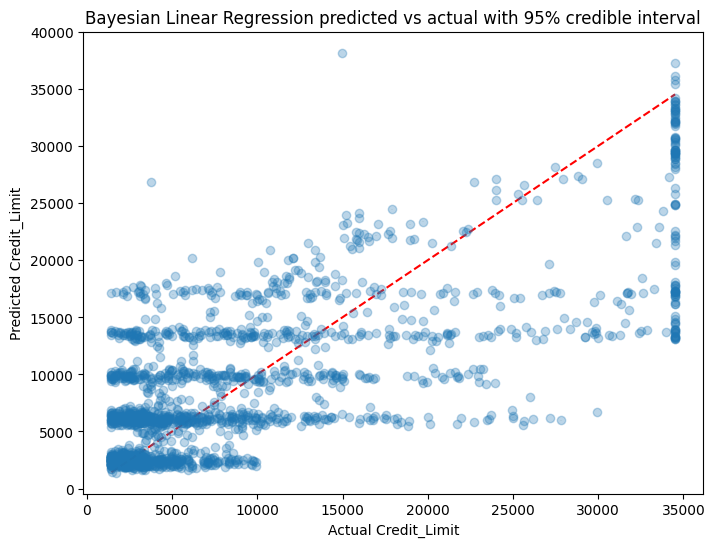

In [11]:
# plot predicted vs actual พร้อม credible interval
plt.figure(figsize=(8,6))
plt.errorbar(yr_test, y_pred, yerr=1.96*y_std, fmt='o', alpha=0.3, ecolor='lightgray')
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual Credit_Limit')
plt.ylabel('Predicted Credit_Limit')
plt.title('Bayesian Linear Regression predicted vs actual with 95% credible interval')
plt.show()

In [ ]:
sk_model = BayesianRidge()
sk_model.fit(Xr_train_scaled.values, yr_train)
y_pred_sk = sk_model.predict(Xr_test_scaled.values)

print("sklearn R²:", r2_score(yr_test, y_pred_sk))
print("weight ของเรา:", model.mu_post.ravel())
print("weight ของ sklearn:", np.r_[sk_model.intercept_, sk_model.coef_])

sklearn R²: 0.5385679388440179
weight ของเราเอง: [ 20379.63083365   3693.81389097 -17694.95021241   1062.70492285
  -1923.43910791   -455.43496201    783.23620549    221.49343663]
weight ของ sklearn: [ 21985.33524864   3691.82002683 -19298.99571075   1057.86784327
  -3522.34786117   -454.30330053   -800.66840192    221.34118176]
